# Random Lightcurve Segment Plots

This notebook samples random files from `lightcurves.LC_DATA_PATH` and plots segmented lightcurves using `cnn.DEFAULT_SPLIT_SIZES`.

In [1]:
import math
import random
from pathlib import Path

from matplotlib import pyplot as plt

from cnn import (
    DEFAULT_SPLIT_SIZES,
    _segment_lightcurve,
    _segment_windows_for_split_size,
)
from lightcurves import LC_DATA_PATH, load


/Users/adam/Code/lc-filter/.venv/lib/python3.13/site-packages/lightkurve/prf/__init__.py:7: UserWarning: Warning: the tpfmodel submodule is not available without oktopus installed, which requires a current version of autograd. See #1452 for details.
  warnings.warn(


In [2]:
N_RANDOM_FILES = 3

fits_files = list(Path(LC_DATA_PATH).rglob('*.fits'))
fits_gz_files = list(Path(LC_DATA_PATH).rglob('*.fits.gz'))
all_files = sorted(set(fits_files + fits_gz_files))

if not all_files:
    raise RuntimeError(f'No FITS files found under {LC_DATA_PATH}')

k = min(N_RANDOM_FILES, len(all_files))
sample_paths = random.sample(all_files, k=k)

print(f'LC_DATA_PATH: {LC_DATA_PATH}')
print(f'Total files found: {len(all_files)}')
print(f'Sampled files ({k}):')
for p in sample_paths:
    print(' -', p)
print('DEFAULT_SPLIT_SIZES:', DEFAULT_SPLIT_SIZES)


LC_DATA_PATH: /Users/adam/Code/lc-simulator/data
Total files found: 31110
Sampled files (3):
 - /Users/adam/Code/lc-simulator/data/lensing/452b9965-3872-4c8d-b91f-83d986863c7c.fits.gz
 - /Users/adam/Code/lc-simulator/data/not-lensing/16542054-62d3-4ced-96bf-7fe4aeda4533.fits.gz
 - /Users/adam/Code/lc-simulator/data/not-lensing/7cc885a8-488b-4a96-8117-46dd4e927aa3.fits.gz
DEFAULT_SPLIT_SIZES: [2, 7, inf]



File: /Users/adam/Code/lc-simulator/data/lensing/452b9965-3872-4c8d-b91f-83d986863c7c.fits.gz


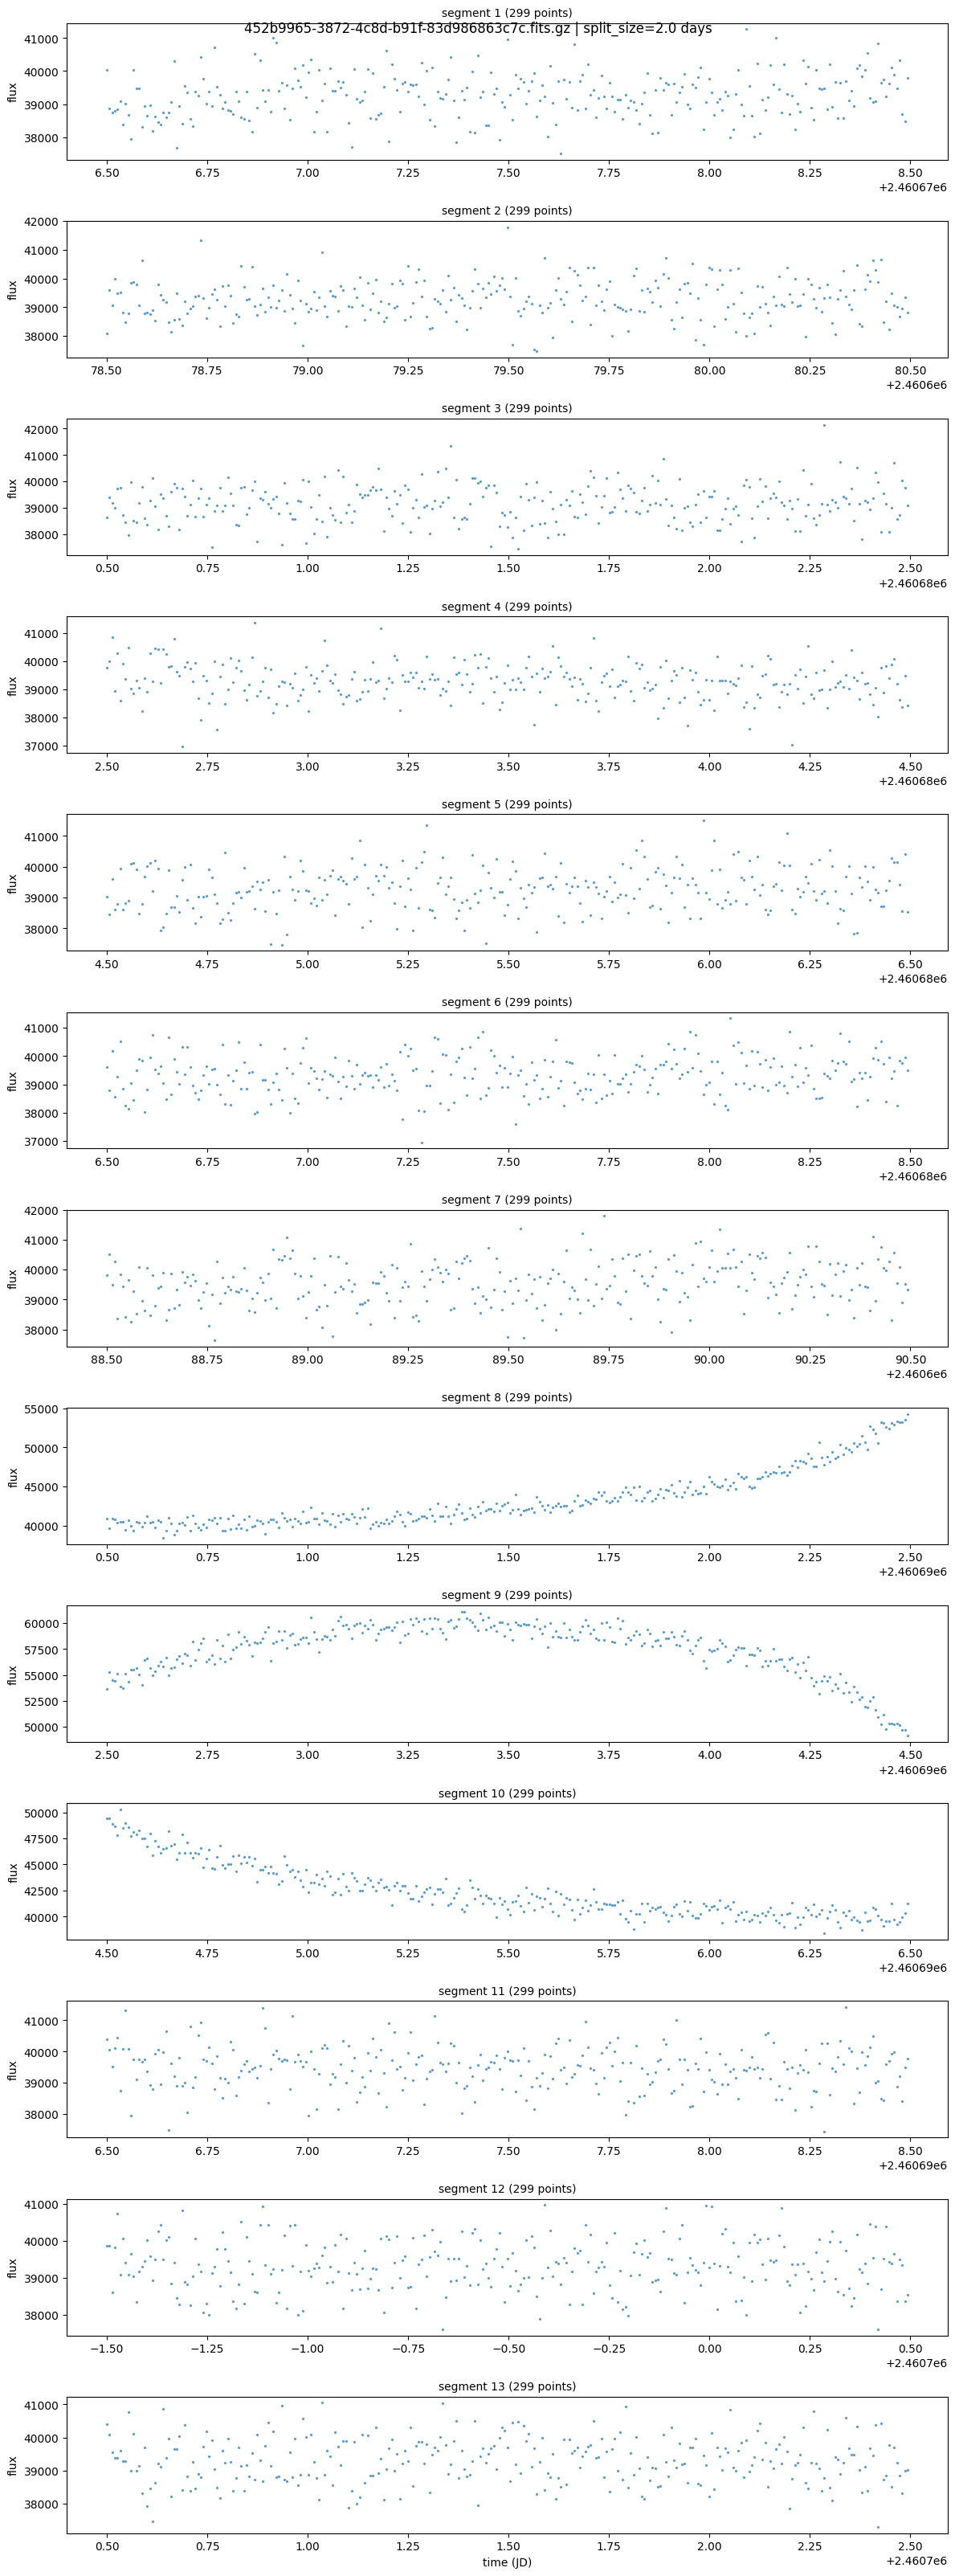

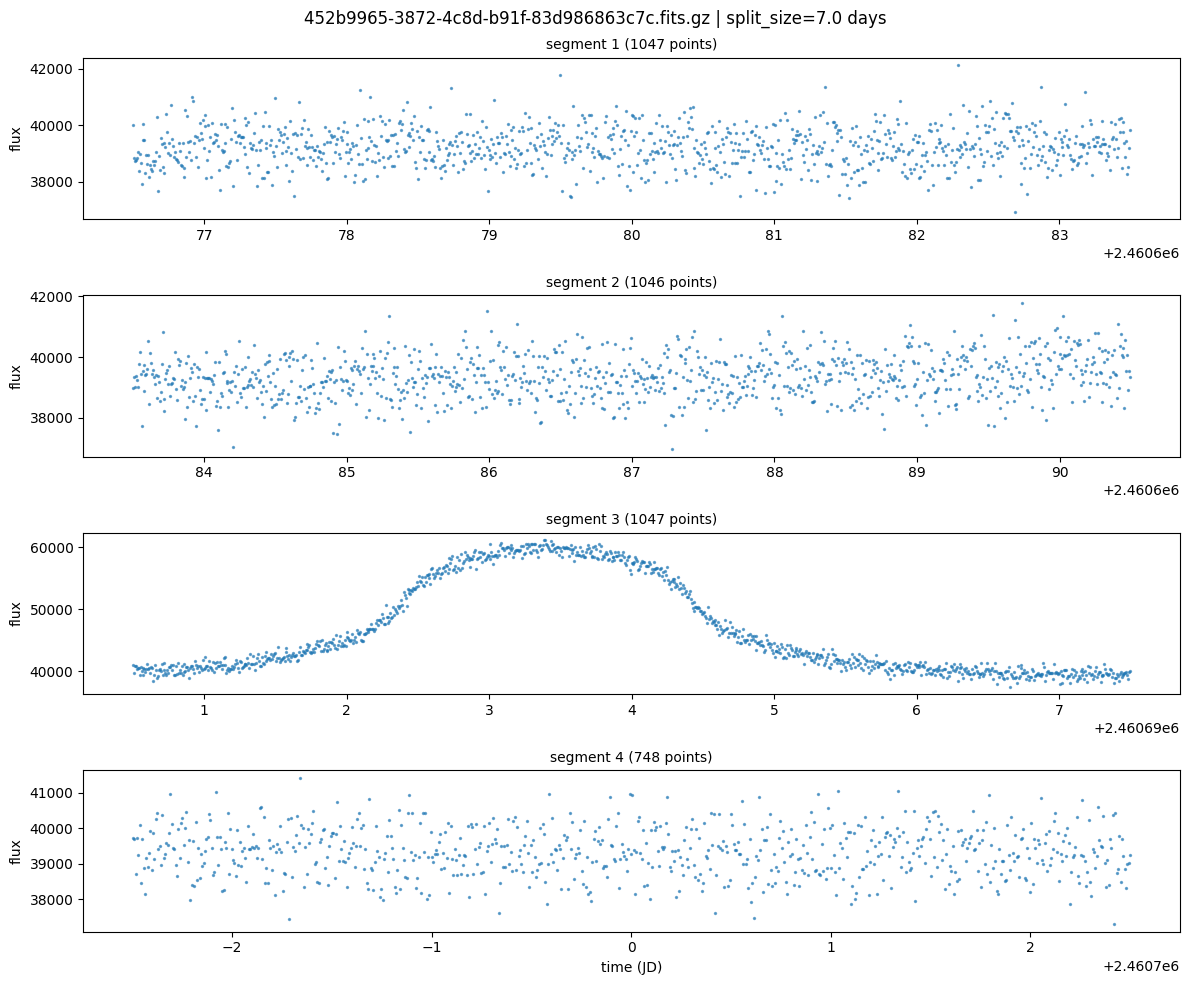

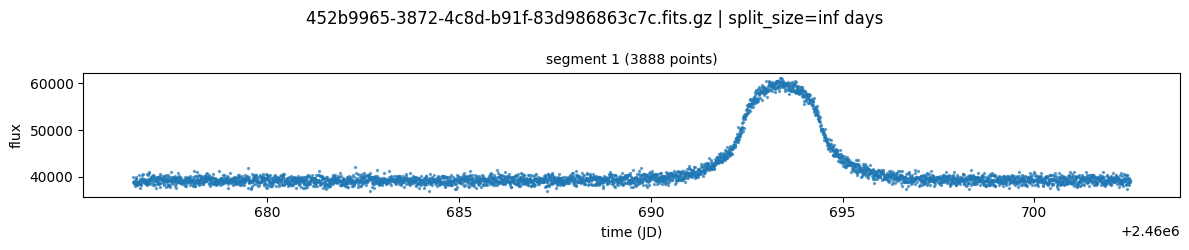


File: /Users/adam/Code/lc-simulator/data/not-lensing/16542054-62d3-4ced-96bf-7fe4aeda4533.fits.gz


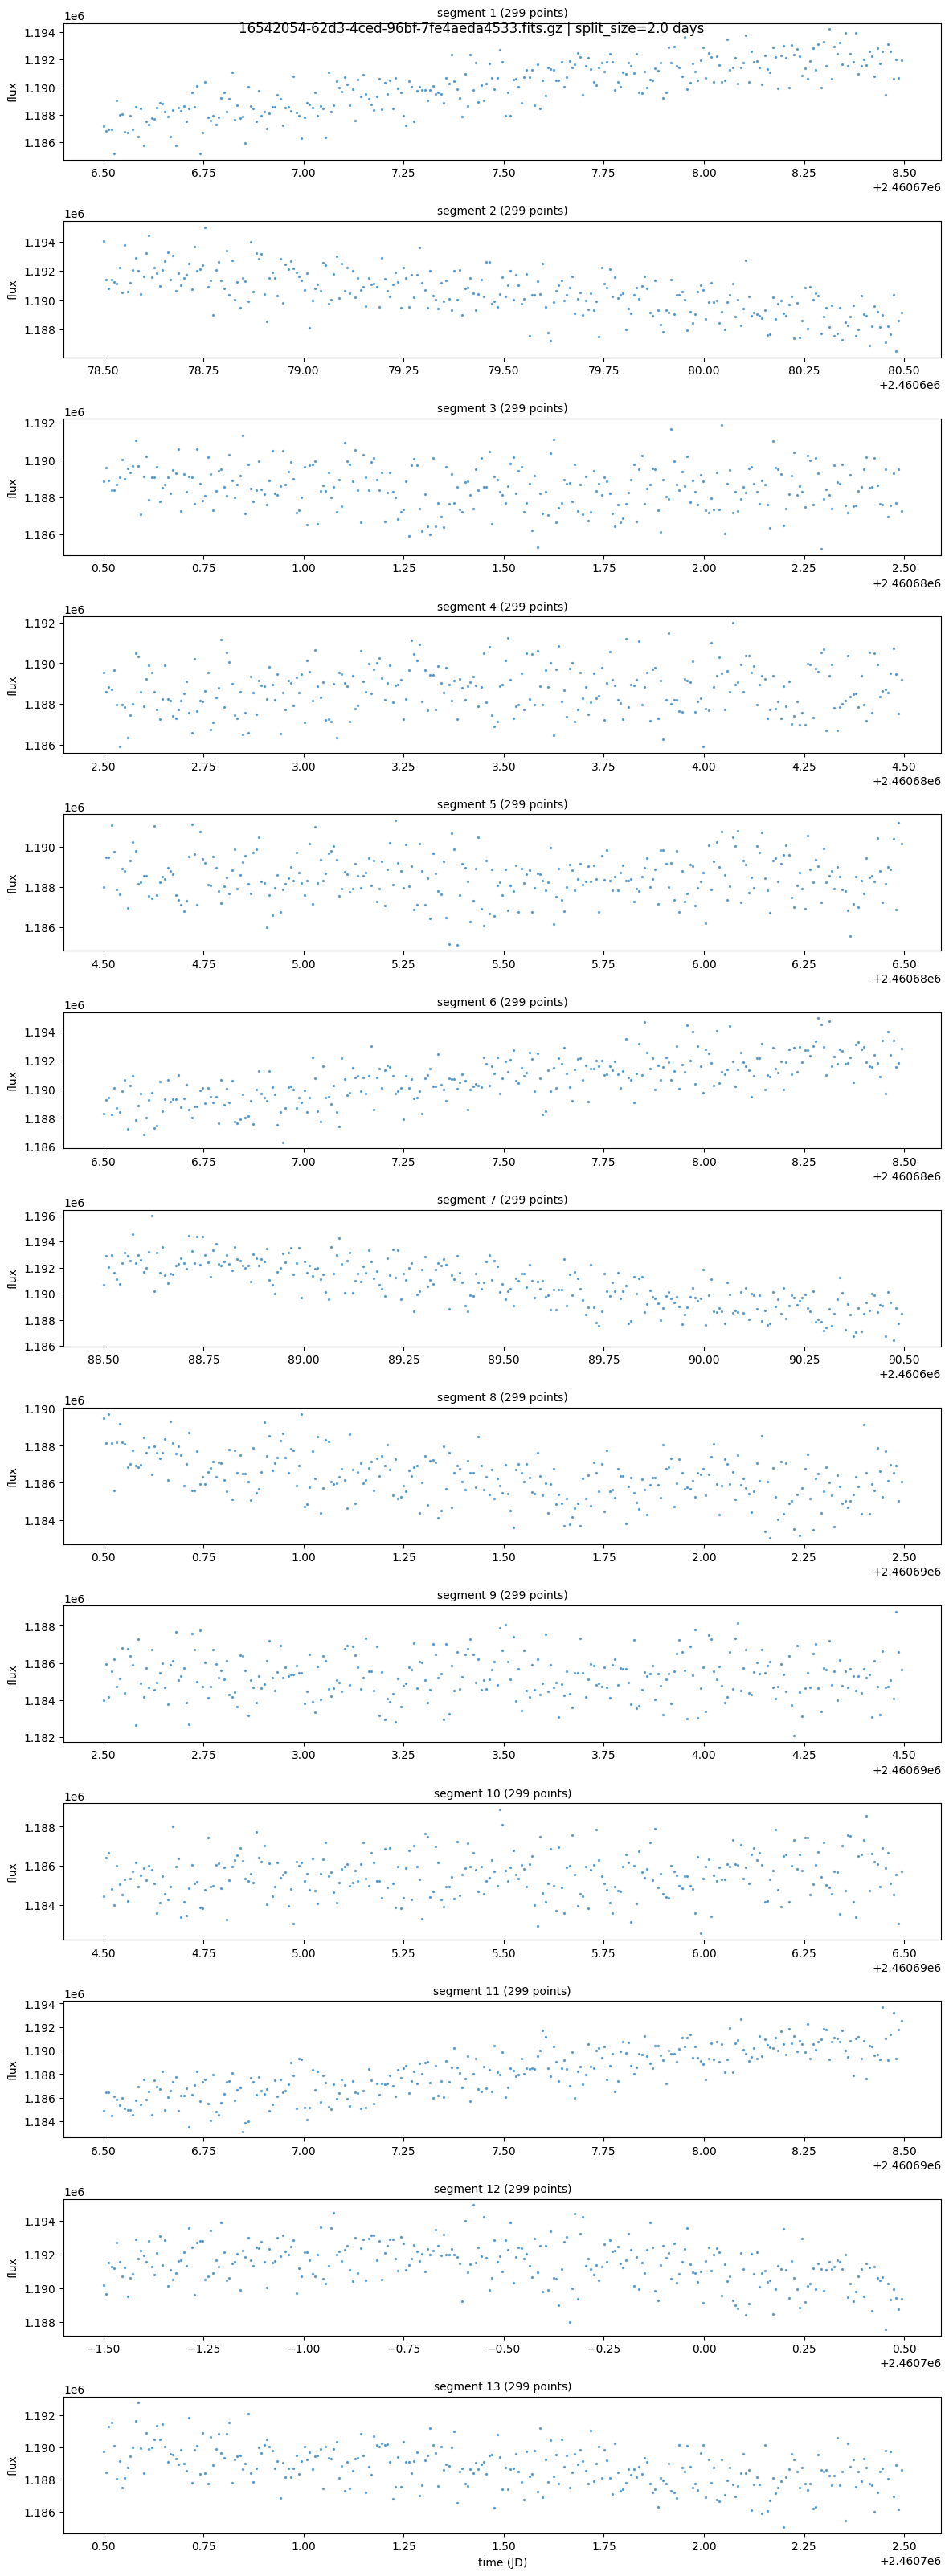

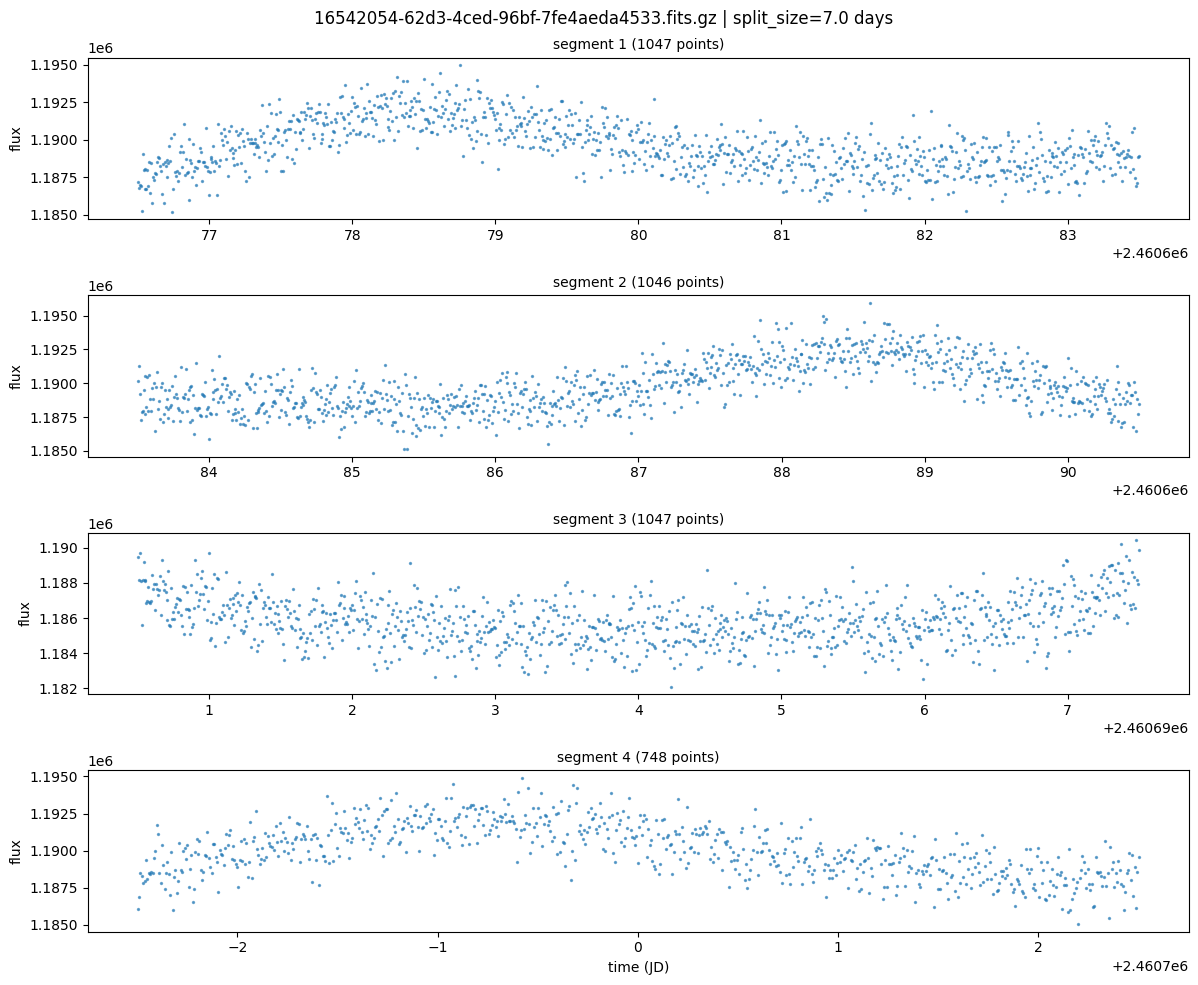

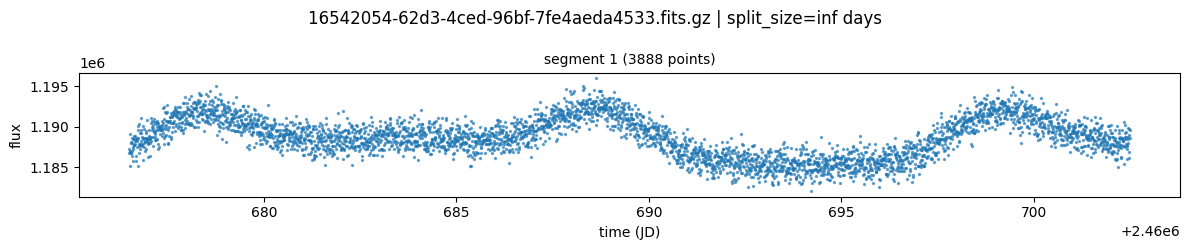


File: /Users/adam/Code/lc-simulator/data/not-lensing/7cc885a8-488b-4a96-8117-46dd4e927aa3.fits.gz


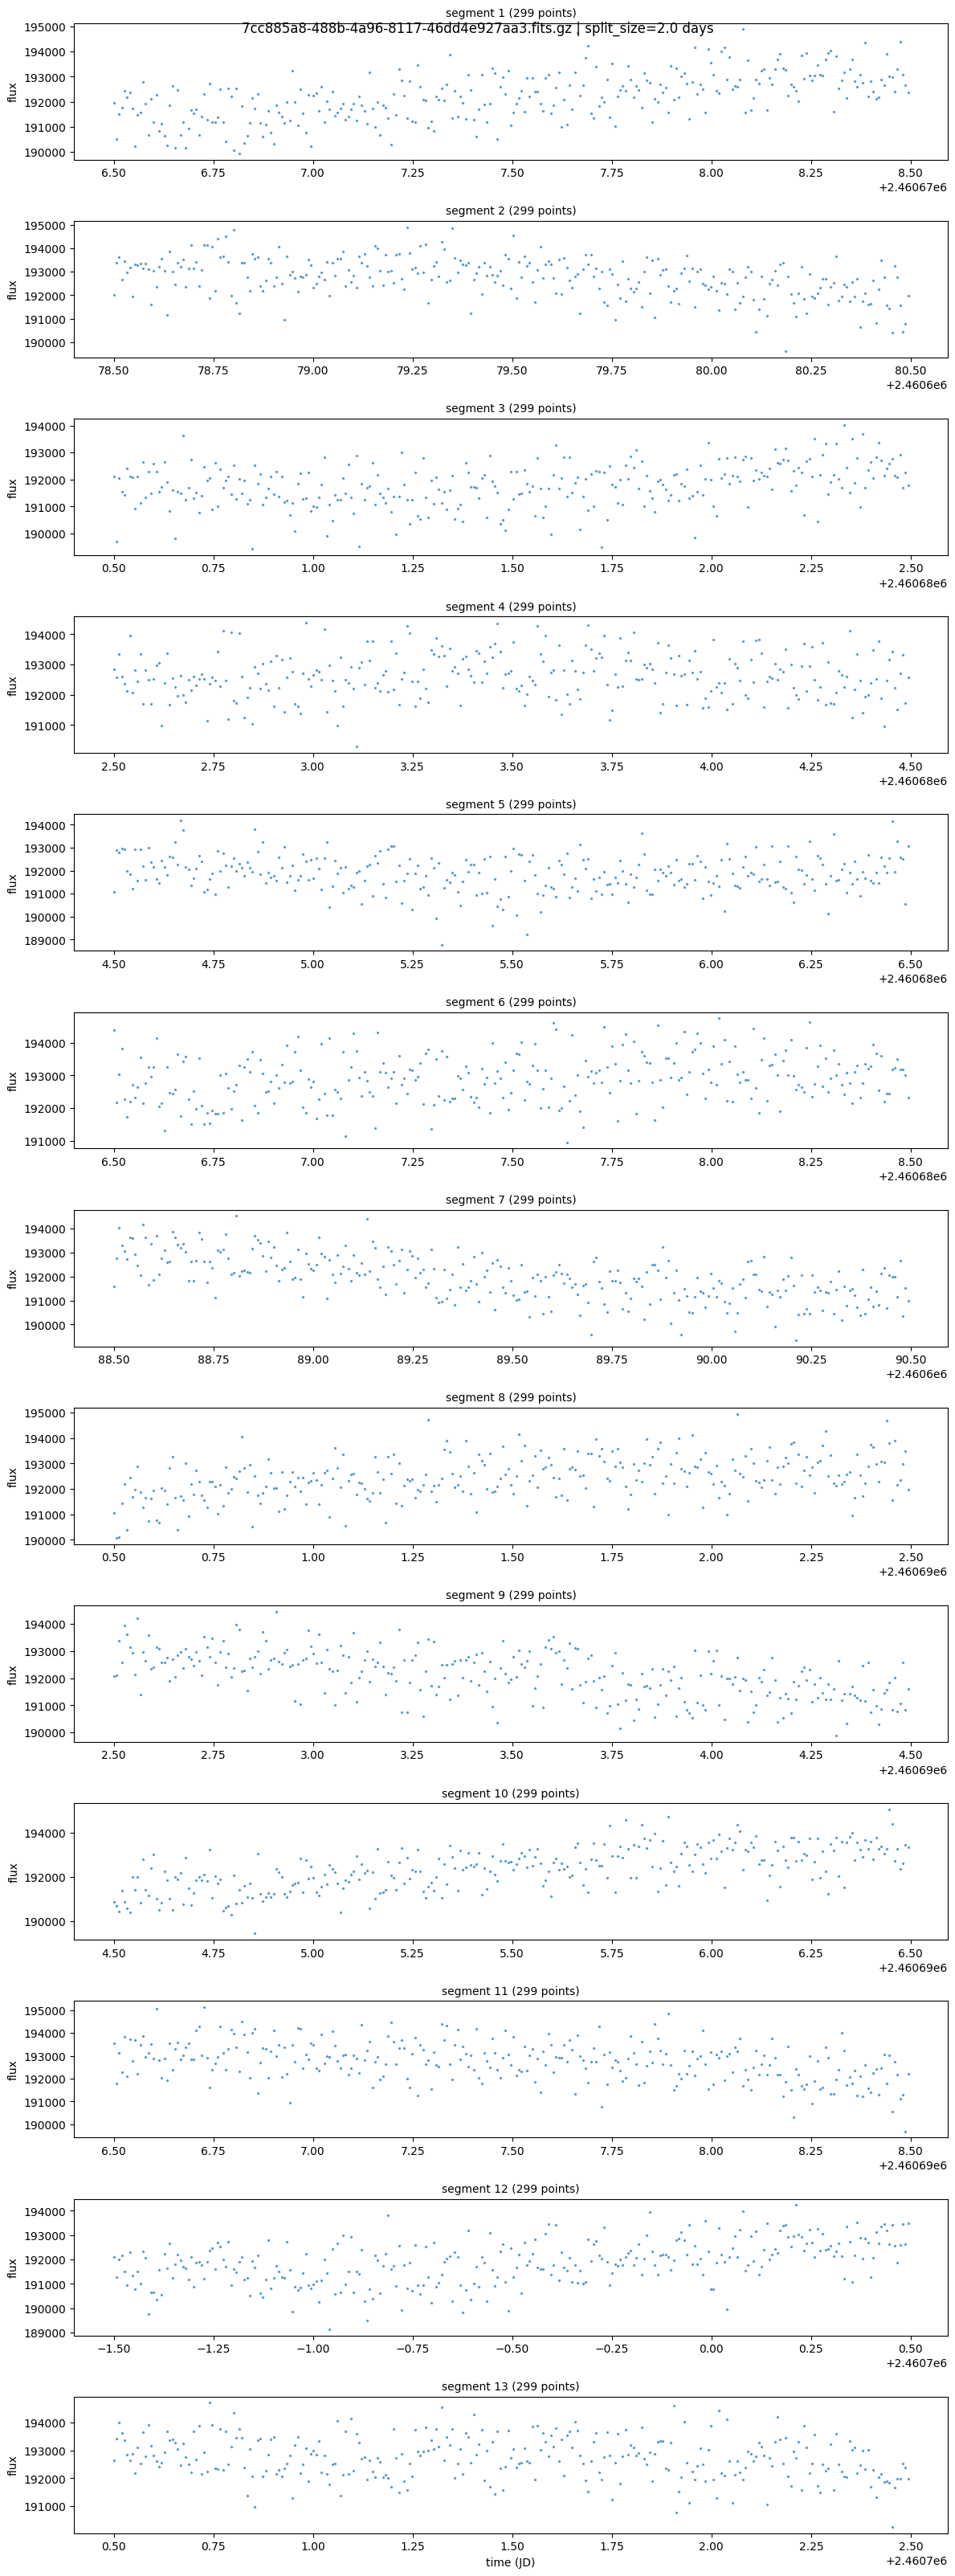

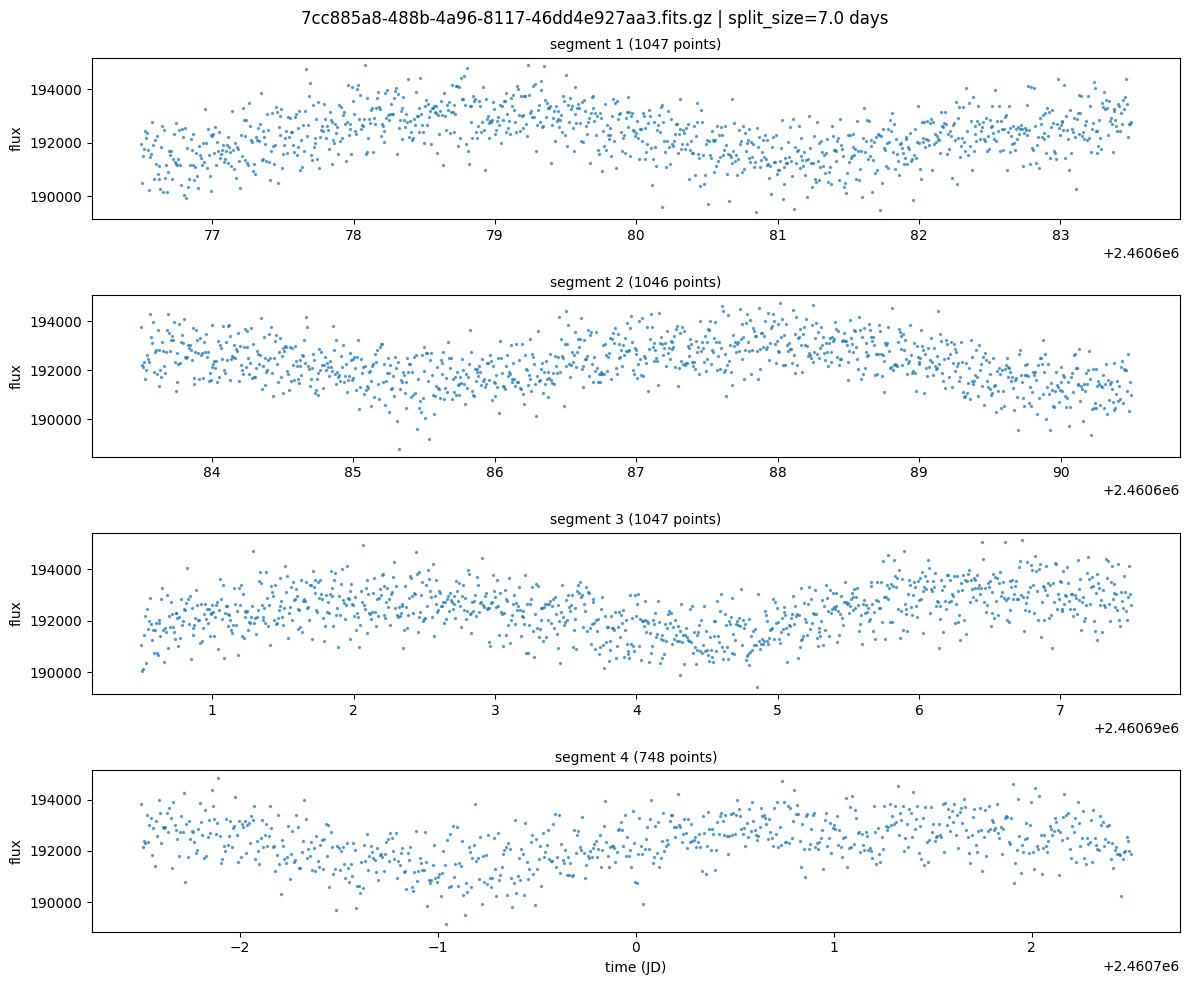

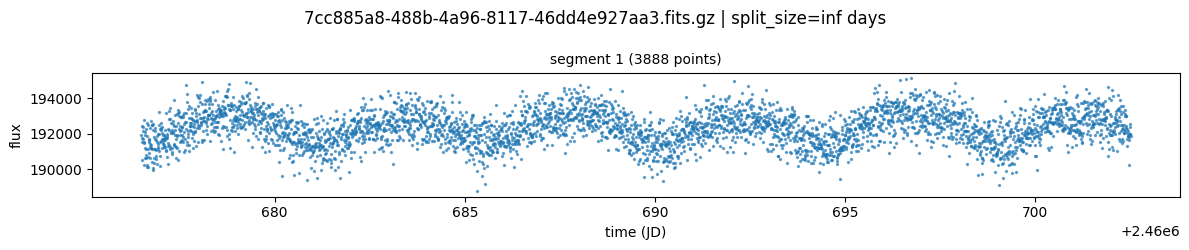

In [3]:
for path in sample_paths:
    lc = load(path)

    print(f'\nFile: {path}')

    for split_size in DEFAULT_SPLIT_SIZES:
        split_size_days = float(split_size)
        windows = _segment_windows_for_split_size(lc, split_size_days)
        segments = [
            _segment_lightcurve(lc, start, end)
            for start, end, _ in windows
        ]
        segments = [seg for seg in segments if len(seg) > 0]

        if not segments:
            print(f'  split_size={split_size_days}: no non-empty segments')
            continue

        fig, axes = plt.subplots(
            len(segments),
            1,
            figsize=(12, max(2.5, 2.5 * len(segments))),
            squeeze=False,
        )
        axes = axes.flatten()

        fig.suptitle(f'{Path(path).name} | split_size={split_size_days} days', fontsize=12)

        for i, seg in enumerate(segments):
            ax = axes[i]
            ax.scatter(seg['time'].jd, seg['flux'], s=2, alpha=0.6)
            ax.set_ylabel('flux')
            ax.set_title(f'segment {i + 1} ({len(seg)} points)', fontsize=10)

        axes[-1].set_xlabel('time (JD)')
        plt.tight_layout()
        plt.show()
